# Assignment 2: Cyber Security Threat Landscape Analysis (EDA)
**Course:** AI in Cyber Security Lab (`ENSP355`)  
**Student:** Yatharth Chopra (`2301420022`) | **Program:** B.Tech CSE (Data Science), Sem 7  
**University:** K.R. Mangalam University | **Faculty:** Monika Khatkar

---

### Objective
Analyse the merged phishing dataset (`12,408` websites) to understand:
1. Overall class balance and per-source composition (`UCI 327` vs `UCI 379`).
2. Distribution of feature codes (`-1 = Phishy`, `0 = Suspicious`, `+1 = Legitimate`) across classes.
3. Which URL/SSL/HTML indicators carry the strongest threat signal (Spearman correlation & Mutual Information).
4. Cumulative risk ("red-flag count") and post-harmonisation source alignment.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import FEATURES, TARGET, SOURCE_A, SOURCE_B, SOURCE_SHORT, CODE_NAMES, load_data

sns.set_theme(style="whitegrid", context="notebook")
BLUE, RED, GREY = "#2a7ab0", "#d1495b", "#9aa5b1"
df = load_data()
print(f"Loaded merged dataset: {df.shape[0]:,} rows x {df.shape[1]} columns | Missing: {int(df.isna().sum().sum())}")

Loaded merged dataset: 12,408 rows x 13 columns | Missing: 0


### 2.1 Class Balance & Source Composition

Raw Result Code by Source (1=Legitimate, 0=Suspicious, -1=Phishing):


result_raw,-1,0,1
source,,,
UCI327_PhishingWebsites,4898,0,6157
UCI379_WebsitePhishing,702,103,548


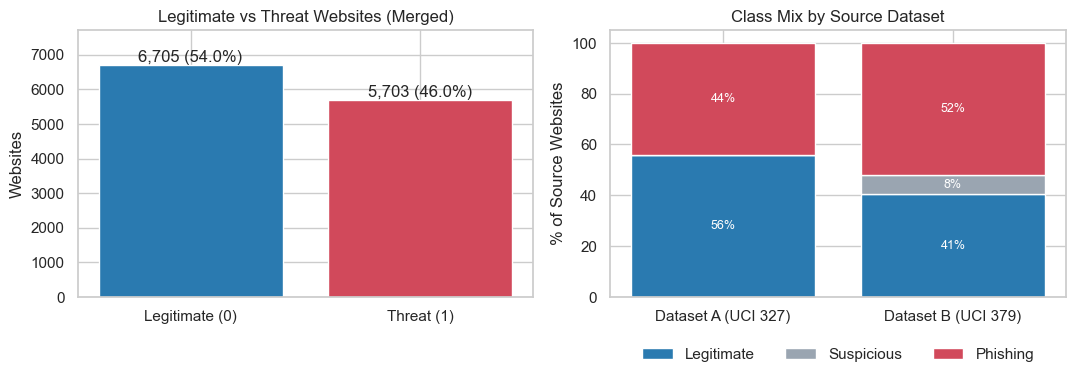

In [2]:
counts = df[TARGET].value_counts().sort_index()
by_source = pd.crosstab(df["source"], df["result_raw"])
print("Raw Result Code by Source (1=Legitimate, 0=Suspicious, -1=Phishing):")
display(by_source)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Legitimate (0)", "Threat (1)"], counts.values, color=[BLUE, RED])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 80, f"{v:,} ({v/len(df):.1%})", ha="center")
axes[0].set_title("Legitimate vs Threat Websites (Merged)")
axes[0].set_ylabel("Websites")
axes[0].set_ylim(0, counts.max() * 1.15)

raw_names = {1: "Legitimate", 0: "Suspicious", -1: "Phishing"}
colors = {1: BLUE, 0: GREY, -1: RED}
bottoms = np.zeros(2)
srcs = [SOURCE_A, SOURCE_B]
for code in [1, 0, -1]:
    vals = np.array([by_source.loc[s].get(code, 0) / by_source.loc[s].sum() * 100 for s in srcs])
    axes[1].bar([SOURCE_SHORT[s] for s in srcs], vals, bottom=bottoms, color=colors[code], label=raw_names[code])
    for i, v in enumerate(vals):
        if v > 4:
            axes[1].text(i, bottoms[i] + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    bottoms += vals
axes[1].set_title("Class Mix by Source Dataset")
axes[1].set_ylabel("% of Source Websites")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### 2.2 Threat Rate by Feature Code & Cumulative Red Flags

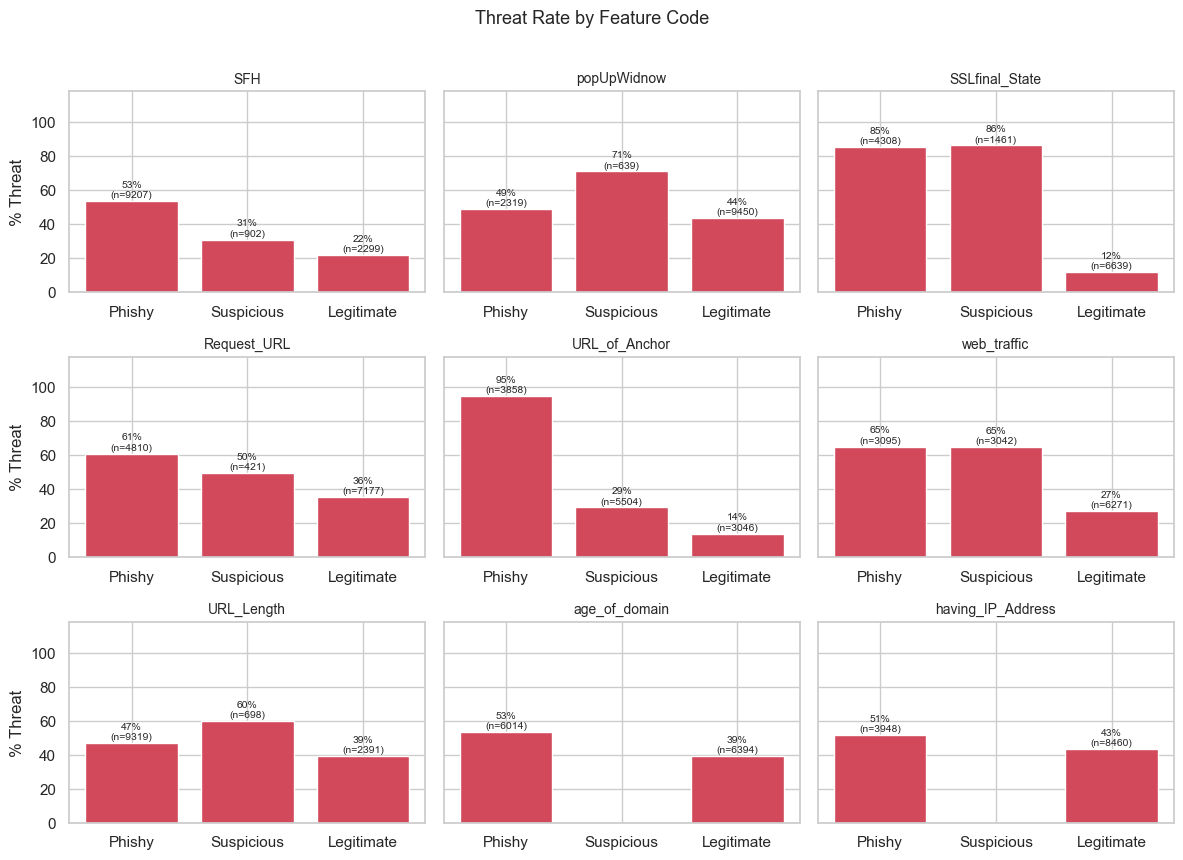

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8.5), sharey=True)
for ax, col in zip(axes.ravel(), FEATURES):
    g = df.groupby(col)[TARGET].agg(["mean", "size"]).reindex([-1, 0, 1])
    ax.bar([CODE_NAMES[c] for c in g.index], g["mean"].fillna(0) * 100, color=RED)
    for i, (m, s) in enumerate(zip(g["mean"], g["size"])):
        if pd.notna(m):
            ax.text(i, m * 100 + 2, f"{m:.0%}\n(n={int(s)})", ha="center", fontsize=7.5)
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 118)
for ax in axes[:, 0]:
    ax.set_ylabel("% Threat")
fig.suptitle("Threat Rate by Feature Code", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

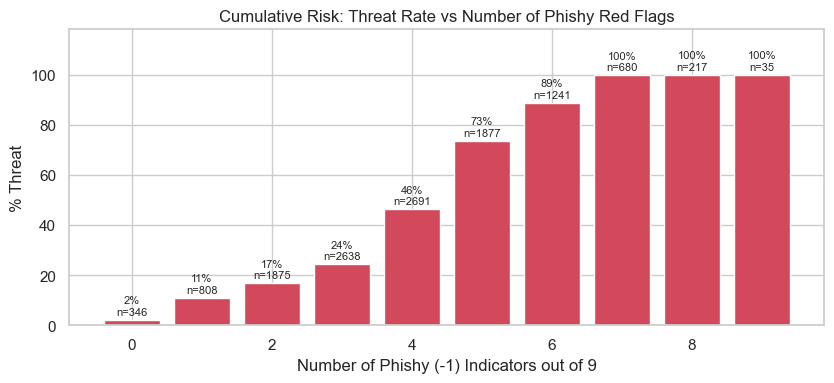

In [4]:
df["red_flags"] = (df[FEATURES] == -1).sum(axis=1)
flags = df.groupby("red_flags")[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(flags.index, flags["mean"] * 100, color=RED)
for k, (m, s) in flags.iterrows():
    ax.text(k, m * 100 + 2, f"{m:.0%}\nn={int(s)}", ha="center", fontsize=8)
ax.set_xlabel("Number of Phishy (-1) Indicators out of 9")
ax.set_ylabel("% Threat")
ax.set_ylim(0, 118)
ax.set_title("Cumulative Risk: Threat Rate vs Number of Phishy Red Flags")
plt.tight_layout()
plt.show()

### 2.3 Spearman Correlation & Mutual Information Ranking

,Spearman_Corr_with_Threat,Mutual_Info_nats
SSLfinal_State,-0.711,0.305
URL_of_Anchor,-0.630,0.259
web_traffic,-0.358,0.073
SFH,-0.258,0.035
Request_URL,-0.247,0.031
age_of_domain,-0.142,0.010
popUpWidnow,-0.074,0.008
URL_Length,-0.035,0.004
having_IP_Address,-0.075,0.003


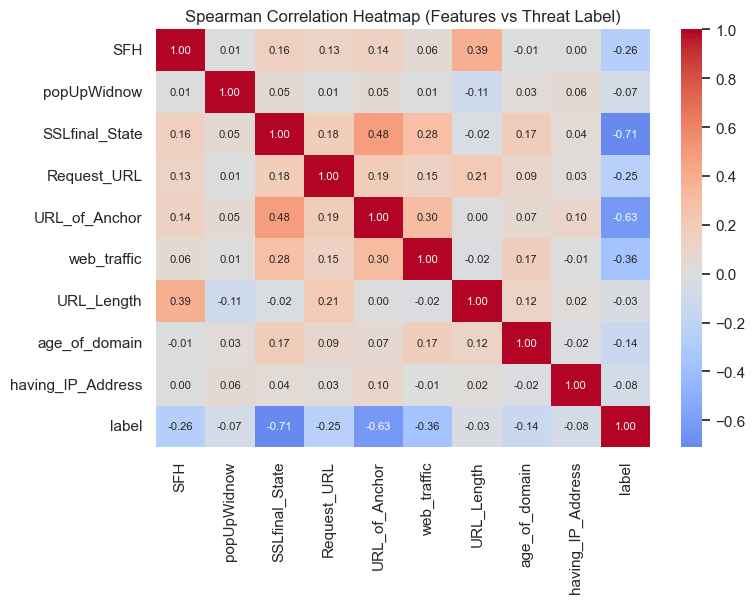

In [5]:
corr = df[FEATURES + [TARGET]].corr(method="spearman")
mi = pd.Series(mutual_info_classif(df[FEATURES], df[TARGET], discrete_features=True, random_state=42), index=FEATURES).sort_values(ascending=False)
ranking = pd.DataFrame({
    "Spearman_Corr_with_Threat": corr[TARGET].drop(TARGET),
    "Mutual_Info_nats": mi,
}).sort_values("Mutual_Info_nats", ascending=False)
display(ranking.round(3))

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman Correlation Heatmap (Features vs Threat Label)")
plt.tight_layout()
plt.show()